# Lithium solvent extraction from oilfield produced water

**The question.** How much lithium can solvent extraction recover from oilfield produced water, how much sodium comes
with it, and on which waters could a continuous process make lithium carbonate worth more than its operating cost?

**Why it matters.**

- **Demand.** Batteries account for about 88 % of global lithium use, and lithium consumption rose by
  about 20 % in 2025 (USGS Mineral Commodity Summaries 2026).
- **Today's sources.** Lithium comes from hard-rock ores and from continental brines that are concentrated in open-air
  evaporation ponds, which lose most of the brine water.
- **Produced water.** Oil and gas wells bring up large volumes of salty water that is managed as a waste. Some of it,
  such as the Smackover water of southern Arkansas, holds tens to a few hundred mg/L of lithium. Solvent extraction can
  take lithium from such a dilute brine without evaporation ponds.
- **The difficulty.** The water holds far more sodium, calcium and magnesium than lithium. Calcium and magnesium
  consume acidic extractants and precipitate with carbonate, so they must be removed (softened out) or tolerated by
  the extractant. Sodium, about 115 ions for every lithium ion in the main water here, competes for the extractant and
  follows lithium toward the product.

**What this notebook does** (about 2 minutes on *Run All*), following the paper it accompanies:

1. builds a three-stage countercurrent extraction in IDAES and PrOMMiS, step by step, and compares four solvent systems;
2. builds the whole process from raw produced water to lithium carbonate for one solvent system and two waters;
3. shows the paper's screen of 14 waters, read from its result files.

## Background

**Solvent extraction** mixes the water (the *aqueous* phase) with an oil-like liquid (the *organic* phase) that holds an
extractant. Lithium moves into the organic, and the two liquids then settle apart. A **stage** is one mix-and-settle
step. In a **countercurrent** cascade the water flows from stage 1 to stage $N$ while fresh organic enters at stage $N$
and flows back, so the water meets the cleanest organic just before it leaves. The loaded organic is then **scrubbed**
(a dilute acid wash removes sodium) and **stripped** (stronger acid returns the lithium to a small volume of water),
and the organic is reused.

**Why ePC-SAFT.** The brine is concentrated salt water, far from an ideal solution: 2.79 mol/L sodium in the
stage-comparison feed, with calcium and magnesium assumed already removed (Step 2.1), and 4.58 mol/L sodium in the
whole-process feed after softening with sodium hydroxide and soda ash (Step 12.2). Its acidity and sodium also change
from stage to stage, so a fixed distribution coefficient cannot predict a multistage extraction. Electrolyte PC-SAFT
(ePC-SAFT) gives the activity of every ion and molecule in both liquids, so each stage is solved as a chemical and phase
equilibrium.

The four solvent systems compared here:

| System | How it takes up lithium |
|---|---|
| Acid-form HBTA/TOPO | HBTA trades a proton (H⁺) for Li⁺; TOPO completes the lithium complex in the organic |
| Sodium-saponified HBTA/TOPO | HBTA is first converted to its sodium form with NaOH, so it trades Na⁺ for Li⁺ instead of releasing acid |
| D2EHDTPA/BuPhen | a sodium-form dithiophosphate trades Na⁺ for Li⁺; BuPhen binds the lithium |
| TBAC:DA/TOPO deep eutectic solvent (DES) | takes up each metal ion together with a chloride ion |

### Glossary

| Term | Meaning |
|---|---|
| MS-2 | a USGS produced-water sample from the Smackover Formation, southern Arkansas (168 mg/L Li) |
| Mars Hill, BR-2, Westmoreland | other USGS samples: two Smackover waters and a Marcellus water from Pennsylvania; numbered waters (USGS 45903) are sample identifiers in the USGS Produced Waters Geochemical Database |
| softening | removing calcium and magnesium by precipitating them with sodium hydroxide and soda ash (Na$_2$CO$_3$) |
| O/A | organic-to-aqueous volume ratio |
| raffinate, loaded organic, strip liquor | the water leaving the last extraction stage; the organic leaving stage 1; the acid solution that receives the lithium |
| $D_M$, $\beta$, $E_{Li}$ | distribution coefficient of metal M (organic over aqueous concentration); separation factor $D_{Li}/D_{Na}$ (selectivity); lithium recovery |
| HBTA, TOPO | benzoyltrifluoroacetone (the acidic extractant) and tri-*n*-octylphosphine oxide (a neutral co-extractant) |
| saponified | extractant pre-reacted with NaOH, so it exchanges sodium, not acid, for lithium |
| D2EHDTPA, BuPhen | bis(2-ethylhexyl)dithiophosphoric acid and 2,9-dibutyl-1,10-phenanthroline |
| TBAC:DA | tetrabutylammonium chloride : decanoic acid |
| LCE | lithium carbonate equivalent: 1 kg of lithium makes 5.32 kg of Li$_2$CO$_3$ |
| operating break-even price | the lithium carbonate price at which the product just pays the operating cost |
| margin | value of the lithium carbonate minus the operating cost, per m$^3$ of raw water |
| single-stage fit, cascade fit | the two fits of the saponified HBTA/TOPO lithium–sodium exchange constant, to single-stage tests and to a three-stage cascade test (Zhang et al.) |
| Engine | the ePC-SAFT equilibrium library |
| Arc | an IDAES connection that makes one unit's outlet stream the next unit's inlet |

## Step 1: Import the tools

The IDAES and PrOMMiS flowsheet pieces, the stage property packages, this project's downstream units, and the tutorial
helpers. Each helper takes the model `m` and does one job (constraints, starting points, figures, checks) that would
otherwise bury the flowsheet steps. The last line lists the software versions.

In [1]:
import lithium_tutorial_tools as tools
import lithium_produced_water_tools as pw
import lithium_solvent_comparison_tools as sc

from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

from prommis.lithium_extraction.process import (
    acid_recovery as chain,
    costing,
    strip_and_carbonation as downstream,
)
from prommis.lithium_extraction.extraction import stage
from prommis.lithium_extraction.extraction.stage import (
    ExtentReactions,
    MolarFlowParameters,
)

tools.versions()

,version
ePC-SAFT Engine,1.3.1
IDAES,2.13.0
PrOMMiS,0.0
Pyomo,6.11.0


## Extraction on softened MS-2 with four solvent systems

Steps 2 to 9 solve the extraction step alone, at 25 °C and 1 atm, on three countercurrent stages:

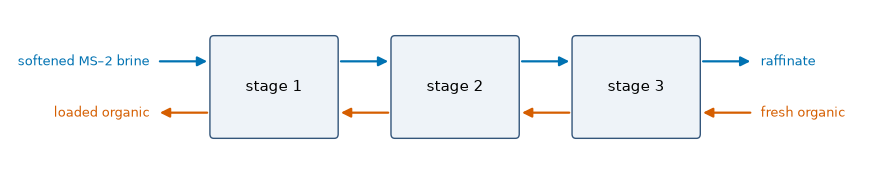

In [2]:
sc.draw_cascade()

### Step 2: Inputs

#### 2.1 The feed

All four systems start from MS-2 with its calcium, magnesium, strontium and barium assumed already removed and no
lithium lost: Li, Na and K from the USGS analysis (168, 64 100 and 2 300 mg/L), chloride by charge balance, and a
small hydrogen-ion amount (the equilibrium pH is calculated). K passes through unchanged. A dash marks a species a
system's model leaves out.

In [3]:
sc.feed_table()

,mol per L feed,mg/L,"model feed, HBTA/TOPO and DES (mol/L)","model feed, D2EHDTPA/BuPhen (mol/L)"
Li,0.0242,168,0.0242,0.0242
Na,2.79,"64,100",2.79,2.79
K,0.0588,"2,300",—,—
water,55.5,—,55.5,55.5
H,1.7e-06,0.00171,1.7e-06,—
Cl,2.87,"101,794",2.81,2.81
Mg,0,0,—,—
Ca,0,0,—,—
Sr,0,0,—,—
Ba,0,0,—,—


#### 2.2 The designs

Each system's **three-stage design for maximum lithium recovery**, from the paper: O/A, the extractant concentration
$c$ and the saponified fraction $r_{Na}$ for HBTA/TOPO; O/A, the BuPhen concentration $B$ and the sodium-form site
supply $S$ for D2EHDTPA/BuPhen; ammonia and TOPO content for the DES. Most optima sit on a design bound.

In [4]:
sc.designs()

value
system                      design variable                                         
Acid HBTA/TOPO              O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.3 (upper bound)
                            r_Na, sodium-form fraction of HBTA                     0
Sodium-saponified HBTA/TOPO O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.4 (upper bound)
                            r_Na, sodium-form fraction of HBTA                 0.992
D2EHDTPA/BuPhen             O/A                                                 1.82
                            B, BuPhen (mol/L organic)              1.0 (upper bound)
                            S, sodium-form sites per mol feed Li   1.5 (upper bound)
TBAC:DA/TOPO DES            ammonia nitrogen (mol per L feed)                0.00512
                            TOPO mass fraction of the organic                  0.325

### Step 3: The chemistry

In acid-form HBTA/TOPO (HBTA written HA, TOPO written T), lithium and sodium enter the organic by releasing a proton:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}},
\qquad \mathrm{M = Li,\ Na}
$$

ePC-SAFT gives the activity $a$ of every species in each liquid, and reaction $r$ is at equilibrium when

$$
\sum_{p,i} \nu_{r,pi} \ln a_{pi} - \ln K_r = 0 ,
$$

with $\nu_{r,pi}$ the stoichiometric coefficient of species $i$ in phase $p$ and $K_r$ the fitted equilibrium constant.
Every Li⁺ extracted releases an H⁺, so the water grows more acidic from stage to stage and holds extraction back. The
other three systems release Na⁺ instead of acid, or take up chloride, which is their main difference.

`sc.acid_hbta_topo()` returns the compiled Engine record (species, conserved totals, equilibrium library), the organic
reference state and the feed in mol per litre. The complexes MA·T are shown as LiA·T and NaA·T.

In [5]:
chemistry, reference, brine = sc.acid_hbta_topo()
tools.species(chemistry)

{'aqueous species': ['water',
  'lithium-cation',
  'sodium-cation',
  'hydrogen-cation',
  'chloride-anion'],
 'organic species': ['diluent',
  'hbta',
  'topo',
  'LiA·T complex',
  'NaA·T complex']}

### Step 4: Build the flowsheet

#### 4.1 Model, flowsheet and property packages

A Pyomo `ConcreteModel` with a steady-state `FlowsheetBlock`, and one property package per phase. Flows are mol/h at
1 L/h of feed, so every flow equals mol per litre of feed.

In [6]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)
m.fs.aqueous_properties = MolarFlowParameters(
    phase="aqueous", species=chemistry.supports[0]
)
m.fs.organic_properties = MolarFlowParameters(
    phase="organic", species=chemistry.supports[1]
)

#### 4.2 Transfer extents

In stage $k$ the amounts leaving equal the amounts entering plus the change made by the extents $\boldsymbol\xi_k$:

$$
\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k ,
\qquad \mathbf C\,\mathbf N = \mathbf 0 ,
$$

where each row of $\mathbf C$ counts one conserved total (Li, Na, exchangeable H, BTA, TOPO), so no extent can create
or destroy any of them.

In [7]:
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistry))

#### 4.3 The extraction unit

One PrOMMiS `SolventExtraction` unit with three stages: water forward from stage 1, organic backward from stage 3.
`label_streams` adds short names: `m.fs.boundary[s]` is the feed of species $s$ and `m.fs.stage[k].outlet[s]` the
amount of $s$ leaving stage $k$. Nothing yet says how much moves between the phases, so many degrees of freedom remain.

In [8]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=3,
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={
        "property_package": m.fs.aqueous_properties,
        "flow_direction": FlowDirection.forward,
    },
    organic_stream={
        "property_package": m.fs.organic_properties,
        "flow_direction": FlowDirection.backward,
    },
)
tools.label_streams(m)
degrees_of_freedom(m)

25

#### 4.4 Equilibrium in every stage

The Engine returns the equilibrium amounts leaving a stage from what enters it,
$n^{out}_{s,k} = \mathcal E_s(\mathbf n^{in}_k;\ T, P)$, as a Pyomo `ExternalFunction` with exact first and second
derivatives.

In [9]:
tools.add_stage_equilibrium(m, [chemistry] * 3)
degrees_of_freedom(m)

10

#### 4.5 Fix the feed

In [10]:
for species, amount in brine.items():
    m.fs.boundary[species].fix(amount)
degrees_of_freedom(m)

5

#### 4.6 The design and the fresh organic

The acid-form design ($r_{Na} = 0$) is fixed, and the fresh organic carries
$n_{HBTA} = n_{TOPO} = \mathrm{O/A}\cdot c\,(1-r_{Na})$ and $n_{NaA{\cdot}T} = \mathrm{O/A}\cdot c\,r_{Na}$ per litre
of feed. The lithium complex leaving any stage may not exceed 72 % of the extractant circulated. The model is now square.

In [11]:
start, design = sc.design("acid_A")
fixed = sc.add_design(m, design, reference)
assert degrees_of_freedom(m) == 0
fixed

,fixed value
O/A,3
"c, HBTA and TOPO each (mol/L organic)",0.3
"r_Na, sodium-form fraction of HBTA",0


### Step 5: Initialize

`sc.initialize` solves the stages one at a time with the Engine, sweeping until the organic leaving each stage stops
changing, and loads that profile into the model as IPOPT's starting point. The lithium left in the water at the start,
in mol per litre of feed:

In [12]:
sc.initialize(m, brine)
tools.stage_profile(m, ["lithium-cation"])

stage,1,2,3
lithium-cation,0.02,0.0174,0.0146


### Step 6: Solve

IPOPT solves all three stages together with exact second derivatives. The design is fixed, so this is a simulation; the
optimality conditions printed below should be near zero.

In [13]:
tools.solve(m, "acid_hbta_topo")["kkt"]

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 1.0000680839006293e-14,
 'multiplier_sign': 0.0}

### Step 7: Results for the acid form

The streams entering and leaving the cascade, in mol per litre of feed:

In [14]:
tools.stream_table(m.fs.extraction, "brine feed")

,aqueous Inlet,aqueous Outlet,organic Inlet,organic Outlet
mol per L of brine feed,,,,
water,55.5,55.5,,
lithium-cation,0.0242,0.0146,,
sodium-cation,2.79,2.76,,
hydrogen-cation,1.7e-06,0.0384,,
chloride-anion,2.81,2.81,,
diluent,,,13,13
hbta,,,0.9,0.862
topo,,,0.9,0.862
LiA·T complex,,,0,0.00961


Lithium recovery is $E_{Li} = (n_{Li,aq,in} - n_{Li,aq,N}) / n_{Li,aq,in}$. Stage by stage, lithium in the water falls
only slowly while H⁺ builds up:

In [15]:
recovery = 1 - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"]
print(f"Lithium recovery: {100 * recovery:.2f} %")
tools.stage_profile(
    m,
    [
        "lithium-cation",
        "sodium-cation",
        "hydrogen-cation",
        "LiA·T complex",
        "NaA·T complex",
    ],
)

Lithium recovery: 39.71 %


stage,1,2,3
lithium-cation,0.02,0.0174,0.0146
sodium-cation,2.78,2.77,2.76
hydrogen-cation,0.0147,0.0239,0.0384
LiA·T complex,0.00961,0.00536,0.00286
NaA·T complex,0.0288,0.0183,0.0116


### Step 8: All four solvent systems

`sc.solve_all` builds and solves all four systems at the paper's designs with the same stage structure. A design is
kept only if IPOPT converged, every stage re-solved on its own by the Engine matches the flowsheet, and every conserved
total balances. The cell also checks that the hand-built acid-form flowsheet above matches the study's own builder.

In [16]:
solved, status = sc.solve_all()
print(
    f"Largest outlet difference, hand-built against the study builder: {sc.largest_outlet_difference(m, solved):.1e} mol/L"
)
status

epcsaft_equilibrium prepared record 1


epcsaft_equilibrium prepared record 2


epcsaft_equilibrium prepared record 3


Largest outlet difference, hand-built against the study builder: 0.0e+00 mol/L


epcsaft_equilibrium prepared record 4


,solved,largest balance error (mol/L),largest stage re-solve difference (mol/L)
system,,,
Acid HBTA/TOPO,True,1.01e-14,6.66e-15
Sodium-saponified HBTA/TOPO,True,1.11e-16,2.13e-14
D2EHDTPA/BuPhen,True,2.22e-16,1.42e-14
TBAC:DA/TOPO DES,True,2.01e-14,7.11e-14


### Step 9: Compare the four systems

For stage 1, where the water enters: $D_M = c_{M,org,1}/c_{M,aq,1}$, $\beta = D_{Li}/D_{Na}$, and the sodium share of
the loaded organic $x_{Na,org} = n_{Na,org,1}/(n_{Li,org,1} + n_{Na,org,1})$. $\Delta n_{Na,org}$ is the net sodium
moved into the organic per m$^3$ of feed, and $n_{Li,aq,N}$ the lithium left in the raffinate.

In [17]:
sc.headline(solved)

,Acid HBTA/TOPO,Sodium-saponified HBTA/TOPO,D2EHDTPA/BuPhen,TBAC:DA/TOPO DES
$E_{Li}$,0.397,> 0.999,0.997,$\approx 1$
$\beta = D_{Li}/D_{Na}$,46.4,163,753,370
"$x_{Na,org}$",0.75,0.979,0.336,0.9
"$\Delta n_{Na,org}$ (mol/m$^3$)",28.8,-88.3,-24.1,218
"$n_{Li,aq,N}$ (mol/L)",0.0146,8.63e-08,8.27e-05,$< 10^{-9}$


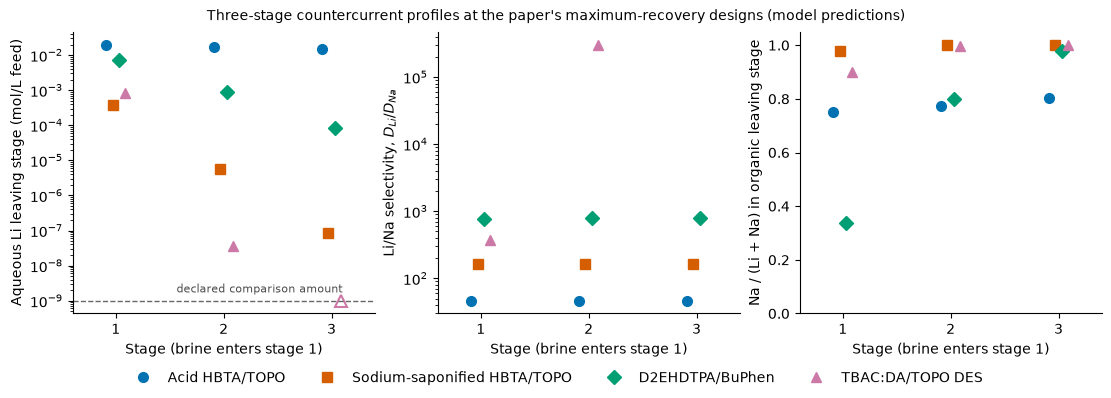

In [18]:
sc.plot_profiles(sc.profiles(solved))

**What this shows.**

- **Acid-form HBTA/TOPO recovers only 39.7 % of the lithium** in three stages (44.9 % in five, in the paper): the acid
  it releases holds extraction back.
- **The other three systems recover nearly all the lithium in three stages**, because they release sodium, not acid,
  or take up chloride with the metal.
- **High recovery does not mean a lithium-rich organic.** With about 115 Na per Li in the feed, sodium is 98 % of the
  metal in the saponified HBTA/TOPO loaded organic and 90 % in the DES, but 34 % for D2EHDTPA/BuPhen. That sodium follows
  the lithium downstream: the HBTA/TOPO process scrubs it from the loaded organic, while the D2EHDTPA/BuPhen process
  removes it from the strip liquor. What decides a process therefore lies after extraction.

## The whole process: saponified HBTA/TOPO from raw water to lithium carbonate

Steps 10 to 20 follow saponified HBTA/TOPO from raw MS-2 water to lithium carbonate, now with softening modeled.

![Block flow diagram of the process](lithium_produced_water_process_block_flow_diagram.png)

*Block flow diagram from the paper (Figure 1). These steps follow the upper lane.*

1. **Softening.** NaOH and soda ash precipitate magnesium and calcium as sludge; HCl returns the water to its pH.
2. **Extraction.** Countercurrent stages with HBTA and TOPO in a kerosene-like diluent, 70 % of the HBTA saponified.
3. **Scrub.** Dilute HCl removes most of the sodium from the loaded organic, losing some lithium.
4. **Strip.** Stronger HCl moves the lithium into the strip liquor; most unused acid is recovered, the rest
   neutralized. The organic is re-saponified and reused, and a small part is lost each pass.
5. **Carbonation.** Soda ash precipitates lithium carbonate from the concentrated strip liquor; most of the mother
   liquor is recycled.

**The worked example.** 1 m$^3$/h of raw water at base-case prices, at a fixed design, so each water is solved once as
a simulation. Each water's design is the cheapest over 1 to 5 stages and 0.1 to 0.4 mol/L HBTA, at O/A = 1 and 70 %
saponification with at least 95 % lithium extraction. The operating cost counts reagents, sludge disposal, and
replacement of 1 % of the organic lost per pass with HBTA priced at 100 USD/kg; energy, capital and labor are excluded.

### Step 10: Inputs

#### 10.1 The two waters

The calcium and magnesium per kilogram of lithium set most of the softening cost.

In [19]:
pw.waters()

,Li (mg/L),Na (mg/L),Ca (mg/L),Mg (mg/L),Cl (mg/L),(Ca+Mg)/Li (kg/kg),selected stages,HBTA (mol/L organic),O/A,saponified fraction
MS-2,168,"64,100","36,900","3,310","174,000",239,5,0.1,1,0.7
Mars Hill,423,"72,500","29,300","2,243","176,679",74.6,5,0.114,1,0.7


#### 10.2 Softening

Two sequential Reaktoro equilibrium doses per litre of raw water: NaOH down to 5 mg/L dissolved magnesium, then soda
ash down to 5 mg/L calcium; HCl then restores the pH. The sludge cake holds 70 % liquid and is washed once; lithium
left in the cake liquid is lost. `pw.soften` reads the stored Reaktoro result.

In [20]:
softened = {site: pw.soften(site) for site in pw.WATERS}
pw.softening_table(softened)

,NaOH (kg/m3 raw),soda ash (kg/m3 raw),"HCl, 31% (kg/m3 raw)",wet sludge (kg/m3 raw),softened water (L per L raw),Ca+Mg left (mg/L),Li kept in softened water (%)
MS-2,11.7,99.3,1.92,343,1,5.45,92.7
Mars Hill,7.4,80,0.24,274,0.997,6.07,94.2


### Step 11: The extraction chemistry

Steps 11 to 17 solve MS-2. Inside extraction, flows are per litre of softened water; downstream units use raw water,
and $v$ (litres of softened water per litre of raw water) converts between them. Each stage reaches equilibrium in the
two metal reactions of Step 3 and in HBTA dissolving into the water, $\mathrm{HA_{(org)} \rightleftharpoons H^+_{(aq)}
+ A^-_{(aq)}}$. Together they give the sodium-for-lithium exchange of the saponified organic,
$\mathrm{Li^+_{(aq)} + NaA{\cdot}T_{(org)} \rightleftharpoons LiA{\cdot}T_{(org)} + Na^+_{(aq)}}$, with the
single-stage fit of its constant.

`pw.starting_profile` solves the stages one at a time with the Engine for a starting point; it also shows in which
stages water autoprotolysis matters, and `pw.stage_chemistries` compiles one Engine record per stage accordingly.

In [21]:
site = "MS2"
water = softened[site][pw.CASE]
v = water["feed_l"]  # L softened water per L raw water
start = pw.starting_profile(site, softened)
chemistries = pw.stage_chemistries(site, start)
print(
    f"{len(chemistries)} stages, {len(set(map(id, chemistries)))} Engine record(s); v = {v:.4f}"
)

5 stages, 1 Engine record(s); v = 1.0036


### Step 12: Build the extraction stages

#### 12.1 The stage build of Step 4, reused

`tools.extraction_flowsheet` runs the statements of Step 4 for five stages. Two more conditions keep the Engine record
consistent: the TOPO it counts follows the extractant, and no stage may leave negative free HBTA or TOPO. The acid-form
model is kept as `acid_form` for the appendix.

In [22]:
acid_form = m  # the acid-form cascade of Steps 4 to 7, used again in the appendix
m = tools.extraction_flowsheet(chemistries, v)
pw.add_extractant_inventory(m, site)

#### 12.2 Feeds

The softened water and the fresh organic (0.10 mol/L HBTA with equal TOPO, 70 % saponified), per litre of softened
water:

In [23]:
pw.feed_extraction(m, site, water)

,softened water,fresh organic
mmol per L of softened water,,
water,"55,508",0
lithium-cation,22.4,0
sodium-cation,"4,584",0
hydrogen-cation,0.00169,0
hydroxide-anion,0,0
bta-anion,0,0
chloride-anion,"4,607",0
hbta,0,30
topo,0,30


#### 12.3 The design

`pw.add_design` adds O/A, the HBTA concentration $c$ and the saponified fraction $r_{Na}$ as fixed variables and writes
the fresh organic in terms of them, as in Step 4.6. The model must be square.

In [24]:
fixed = pw.add_design(m, site, water)
assert degrees_of_freedom(m) == 0
fixed

,value
organic_to_aqueous_ratio,1
extractant_mol_l,0.1
saponification_ratio,0.7


### Step 13: Initialize and solve the extraction stages

As in the IDAES tutorials, one part is solved before the connected flowsheet. `pw.check_extraction` then re-solves
every stage on its own with the Engine and requires agreement with the flowsheet.

In [25]:
stage.initialize(m, pw.stage_amounts(start))
print("Optimality conditions:", tools.solve(m, "MS2_extraction")["kkt"])
extraction = pw.check_extraction(m)
print(
    f"Lithium extraction: {100 * value(m.fs.design.li_extraction):.2f} % of the softened water's lithium"
)
tools.stream_table(m.fs.extraction, "softened water")

Optimality conditions: {'stationarity': 0.0, 'complementarity': 0.0, 'feasibility': 3.552713678800501e-14, 'multiplier_sign': 0.0}


Lithium extraction: 99.53 % of the softened water's lithium


epcsaft_equilibrium prepared record 5


,aqueous Inlet,aqueous Outlet,organic Inlet,organic Outlet
mol per L of softened water,,,,
water,55.5,55.5,,
lithium-cation,0.0224,0.000106,,
sodium-cation,4.58,4.61,,
hydrogen-cation,1.69e-06,2.91e-11,,
chloride-anion,4.61,4.61,,
hydroxide-anion,0,0.00011,,
bta-anion,0,0.0046,,
diluent,,,4.33,4.33
hbta,,,0.03,0.0301


### Step 14: Choose the downstream alternative

Two discrete choices: whether the scrub acid follows its source ratio or the metals it removes, and which interval of
the measured lithium carbonate solubility table the carbonation salt level falls in. The first admissible combination
is used. `pw.downstream_accounts` computes the closed-form downstream balances and prices used to start the units.

In [26]:
candidate, alternatives = pw.downstream_alternatives(m, site, softened)
assumptions, accounts = pw.downstream_accounts(m, site, candidate)
alternatives

combinations checked                                      16
admissible combinations                                    1
selected: scrub acid set by                     source ratio
selected: carbonation NaCl interval (mol/kg)        2 to 2.5
Name: downstream alternative, dtype: object

### Step 15: Add the downstream units

#### 15.1 Scrub and strip

Two single-stage PrOMMiS `SolventExtraction` units, each transferring a specified fraction of the metal on the entering
organic to the acid:

$$
\mathrm{MA{\cdot}T_{(org)} + H^+_{(aq)} \longrightarrow M^+_{(aq)} + HA_{(org)} + T_{(org)}},
\qquad n_{M,aq}^{out} = f_M\, n_{M,org}^{in}
$$

- scrub: 1 mol/L HCl at one tenth of the organic flow; $f_{Na} = 0.90$, the lower bound of sodium removal, and
  $f_{Li} = 0.10$, the lithium loss, both from Zhang et al. (2018, Section 3.1.5);
- strip: 2.5 mol/L HCl at one tenth of the organic flow; $f_{Li} = 0.95$, measured by Zhang et al. (2017, Fig. 6), and
  $f_{Na} = 1$, a model assumption that all remaining sodium is stripped.

In [27]:
pw.add_scrub_and_strip(m, assumptions, candidate, accounts)

#### 15.2 Acid recovery, neutralization and concentration

A `Separator` returns 90 % of the unused strip acid, a `Mixer` neutralizes the rest with NaOH, and a `Separator`
concentrates the liquor to 1 mol Li per kg of water.

In [28]:
downstream.liquor_properties(m.fs)
concentrate = chain.aqueous(
    m.fs, assumptions, m.fs.design.organic_to_aqueous_ratio * v, m.fs.strip.metals["Li"]
)

initializer (constant or callback function) completely masks the default value


universal initializer (constant or callback function) completely masks the
default value


universal initializer (constant or callback function) completely masks the
default value


universal initializer (constant or callback function) completely masks the
default value


#### 15.3 Organic reuse

The stripped organic loses 1 % per pass and is topped up with fresh HBTA, TOPO and diluent; a single-stage
`SolventExtraction` re-saponifies 70 % of the HBTA. The prepared organic is checked against the extraction's organic
feed after the solve.

In [29]:
chain.organic(m.fs, m, assumptions, v, "hbta")

#### 15.4 Carbonation

A `Mixer` joins the concentrate, soda ash and recycled mother liquor; the PrOMMiS `Precipitator` forms
$\mathrm{Li_2CO_{3(s)}}$ at 70 °C; a `Separator` recycles 90 % of the mother liquor. The lithium left dissolved follows
the measured Li$_2$CO$_3$ solubility in NaCl solutions (Ge et al. 2025, Table 4). This call also turns every Arc into
equality constraints.

In [30]:
downstream.connect(m.fs, concentrate, assumptions, candidate, accounts)

#### 15.5 Initialize the downstream units

Solved in sequence, block by block, with the extraction held at its solution.

In [31]:
pw.initialize_downstream(m, assumptions, accounts)

#### 15.6 Costing

An IDAES `FlowsheetCostingBlock` prices each consumed item. At 1 m$^3$/h of raw water,

$$
C_{op} = \sum_j p_j\, \dot m_j \ \ [\mathrm{USD/m^3}], \qquad
C_{Li} = \frac{C_{op}}{\dot m_{Li}} \ \ [\mathrm{USD/kg\ Li}], \qquad
P_{LCE}^{\,\text{break-even}} = \frac{C_{Li}}{5.32} .
$$

In [32]:
flows, lithium_kg_h = pw.priced_flows(m, accounts)
costing.attach(m.fs, flows, lithium_kg_h)
degrees_of_freedom(m)

0

### Step 16: Solve the whole process

One IPOPT solve covers extraction, scrub, strip, acid recovery, neutralization, concentration, organic reuse,
carbonation and costing. `pw.whole_process_result` then re-solves every stage with the Engine, recomputes the
balances and costs, and requires every process limit (95 % lithium extraction, organic loading) to hold.

In [33]:
kkt = tools.solve(m, "MS2_whole_process")["kkt"]
result = pw.whole_process_result(m, site, softened)
kkt

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 2.842170943040401e-14,
 'multiplier_sign': 0.0}

### Step 17: Results for MS-2

#### 17.1 Recovery and cost

Extraction is the share of the softened water's lithium the organic takes up; recovery is the share of the raw water's
lithium that ends in the product.

In [34]:
pw.headline(m, result, softened, site)

Li extraction (%)                          99.5
Li recovery to Li2CO3 (%)                    69
Li2CO3 product (kg per m3 raw water)      0.617
operating cost (USD per m3 raw water)       228
operating cost (USD per kg Li)            1,968
break-even price (USD per t LCE)        369,748
Name: MS-2, dtype: float64

#### 17.2 Lithium through the process

Grams of lithium per m$^3$ of raw water, with every loss.

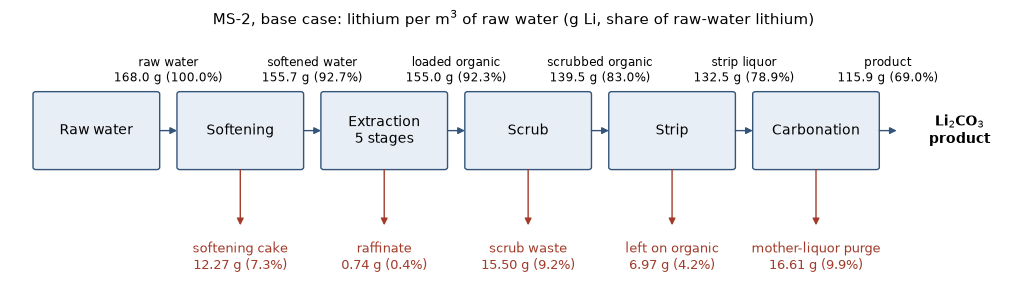

Lithium balance residual (raw water minus product and losses): 6.2e-16 mol per L of raw water


In [35]:
pw.lithium_diagram(result, site)

#### 17.3 Stream tables

Every stream in mmol per litre of raw water: aqueous streams by element, organic streams by species.

In [36]:
aqueous_streams, organic_streams = pw.stream_tables(result)
aqueous_streams

,Li,Na,K,Ca,Mg,Sr,Cl,H,OH,C,BTA,water
washed extraction feed,22.4,"4,601",54.5,0.116,0.0323,0.0214,"4,643",15.5,,1.06,,"51,177"
physical raffinate,0.106,"4,628",54.5,0.116,0.0323,0.0214,"4,643",15.5,0.111,1.06,4.62,"51,177"
saponification NaOH input,,70.3,,,,,,,70.3,,,
scrub HCl input,,,,,,,100,100,,,,
scrub waste,2.23,38.9,,,,,100,59.3,,,,
gross strip HCl input,,,,,,,251,251,,,,
recovered unused strip HCl,,,,,,,205,205,,,,
strip liquor before neutralization,19.1,4.32,,,,,46.2,22.7,,,,
regeneration lithium discharge,1,,,,,,,,,,,
neutralization NaOH input,,22.7,,,,,,,22.7,,,


In [37]:
organic_streams

,hbta,topo,LiA·T complex,NaA·T complex,diluent,BTA_total,TOPO_total,HBTA,TOPO
saponified organic input,30.1,30.1,0,70.3,"4,343",,,,
loaded organic,30.2,34.8,22.3,43.2,"4,343",,,,
organic loss,,,,,43.4,0.957,1,,
regenerated organic,,,,,"4,300",94.8,99.4,,
organic make-up input,,,,,43.4,,,5.58,1


#### 17.4 Operating cost

HBTA replacement dominates: HBTA dissolves into the raffinate on every pass on top of the 1 % loss, at 100 USD/kg.

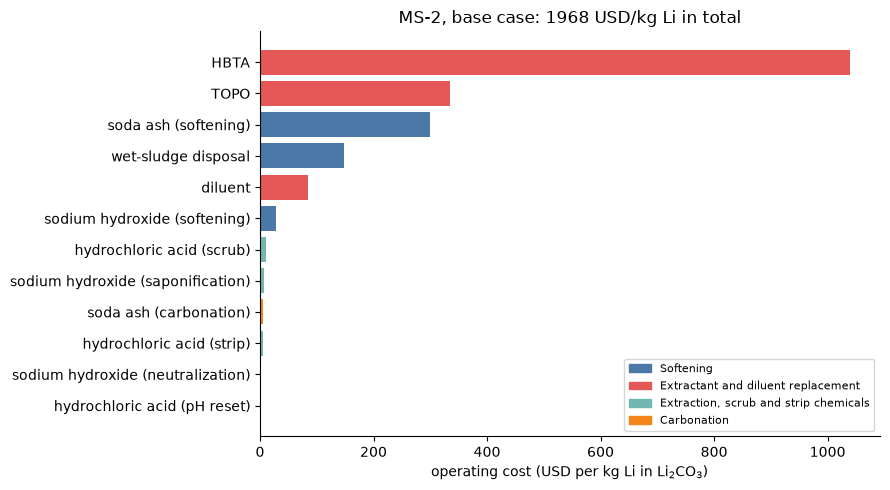

,USD/m3 raw water,USD/kg Li
step,,
Softening,55.4,478
Extractant and diluent replacement,169,"1,460"
"Extraction, scrub and strip chemicals",2.8,24
Carbonation,0.7,6.1


In [38]:
costs = pw.costs(m)
pw.plot_costs(costs, site, result["cost_usd_kg_li"])
costs.groupby("step", sort=False)[["USD/m3 raw water", "USD/kg Li"]].sum().round(1)

### Step 18: Mars Hill

`pw.run_water` solves Mars Hill at its own design with the project's flowsheet builders, which write the same units as
Steps 11 to 16.

initializer (constant or callback function) completely masks the default value


universal initializer (constant or callback function) completely masks the
default value


universal initializer (constant or callback function) completely masks the
default value


universal initializer (constant or callback function) completely masks the
default value


epcsaft_equilibrium prepared record 6


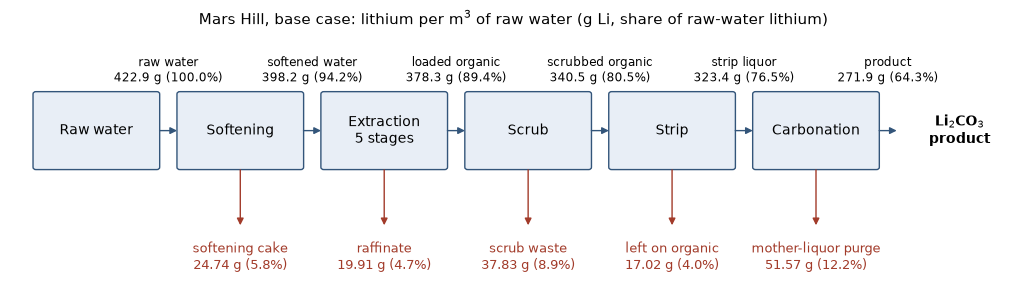

Lithium balance residual (raw water minus product and losses): 5.9e-16 mol per L of raw water


In [39]:
results = {site: result}
mars_hill, results["MarsHill"] = pw.run_water("MarsHill", softened)
pw.lithium_diagram(results["MarsHill"], "MarsHill")

### Step 19: MS-2 against Mars Hill

Mars Hill has 2.5 times the lithium of MS-2 and less than a third of its calcium and magnesium per kilogram of lithium.

In [40]:
pw.summary(results)

,MS-2,Mars Hill
extraction stages,5,5
HBTA (mol/L organic),0.1,0.114
Li extraction (%),99.5,95
Li recovery to Li2CO3 (%),69,64.3
Li2CO3 product (kg per m3 raw),0.617,1.45
operating cost (USD/kg Li),"1,968",750
operating cost (USD/m3 raw water),228,204
break-even price (USD/t LCE),"369,748","140,947"


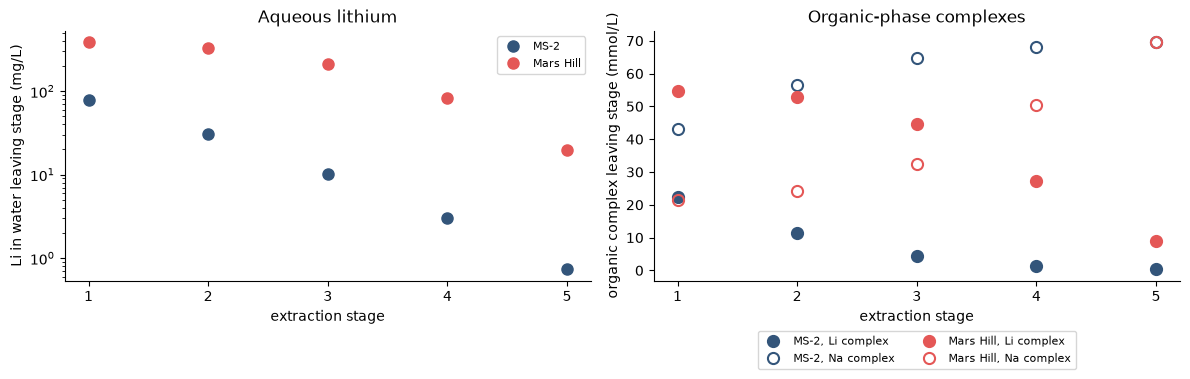

In [41]:
pw.plot_profiles(results)

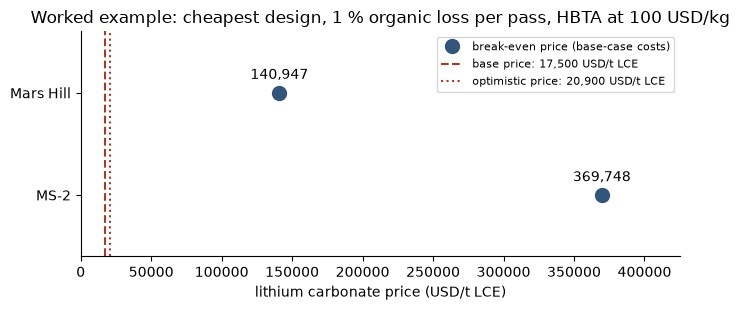

,break-even (USD/t LCE),times base price
MS-2,"369,748",21.1
Mars Hill,"140,947",8.05


In [42]:
pw.plot_break_even(results)

Neither water reaches operating break-even on this basis: MS-2 needs about 21 times and Mars Hill 8.05 times the
base lithium carbonate price (17,500 USD/t LCE). This worked example charges a 1 % organic loss per pass with HBTA at
100 USD/kg. The screen below leaves extractant purchase out of its margin and gives Mars Hill HBTA/TOPO −21.4 USD/m$^3$
at base prices and +5.63 USD/m$^3$ at optimistic prices, a Borderline label.

### Step 20: How the process model is connected

The whole process is one IDAES flowsheet of standard unit models. Each row is one unit, its model class and its ports.

In [43]:
tools.unit_models(m)

,model class,ports
unit,,
extraction,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."
acid_recovery,Separator,"inlet, recovered, liquor"
strip_liquid,Translator,"inlet, outlet"
neutralization,Mixer,"acid, caustic, outlet"
neutral_projection,Translator,"inlet, outlet"
concentration,Separator,"inlet, concentrate, recycle"
regeneration,Translator,"inlet, outlet"
regenerated,Separator,"inlet, organic, lithium_discharge"
organic_loss,Separator,"inlet, organic kept for reuse, loss"


Arcs connect the units. The loaded organic reaches the scrub through the equations of Step 15.1, and the prepared
organic is compared with the extraction's organic feed rather than recycled into it.

In [44]:
tools.arcs(m)

,from,to
arc,,
strip.scrubbed_organic,scrub.unit.organic_outlet,strip.unit.organic_inlet
acid_recovery.feed,strip.unit.aqueous_outlet,acid_recovery.inlet
strip_liquid.feed,acid_recovery.liquor,strip_liquid.inlet
neutralization.feed,strip_liquid.outlet,neutralization.acid
neutral_projection.feed,neutralization.outlet,neutral_projection.inlet
concentration.feed,neutral_projection.outlet,concentration.inlet
regeneration.feed,strip.unit.organic_outlet,regeneration.inlet
regenerated.feed,regeneration.outlet,regenerated.inlet
organic_loss.feed,regenerated.organic,organic_loss.inlet


## The paper's screen of 14 produced waters

The paper applies one design rule, one price table and one solvent-loss rule to six solvent systems on 14 measured
waters; two reach a rated result. The table gives each combination's **margin** at base and optimistic prices and its
research-interest label: **Strong lead** for a positive base margin, **Promising** for a positive optimistic margin and
a base margin of at least −0.5 USD/m$^3$, **Borderline** for an optimistic margin of at least −0.5 USD/m$^3$, and
**Poor** below that. The HBTA/TOPO margin leaves out extractant purchase (TOPO has no published price); the
D2EHDTPA/BuPhen margin includes lost ligand at prices estimated from reagent costs. Read from the paper's result files,
not solved here.

In [45]:
pw.paper_headline()

Assumed lithium carbonate price: 17,500 (base) to 20,900 (optimistic) USD/t LCE


water                     \
             Li (mg/L) (Ca+Mg)/Li (kg/kg)   
USGS 45903         440                110   
Mars Hill          423               74.6   
BR-2               252                171   
USGS 1005          208                129   
USGS 1570          202               77.6   
MS-2               168                239   
Westmoreland       117               27.3   
DM-5               105                349   
USGS 115047        100                114   
USGS 1568           93                 50   
USGS 20492        90.1                290   
USGS 45101          61                700   
USGS 103144         56               72.6   
USGS 115557         30               36.7   

             saponified HBTA/TOPO, softened water                             \
                             base margin (USD/m3) optimistic margin (USD/m3)   
USGS 45903                                    -46                      -6.11   
Mars Hill                                   -21.4                       5.63   
BR-2                                        -46.9                      -15.5   
USGS 1005                                   -42.5                        -14   
USGS 1570                                   -15.8                      0.141   
MS-2                                        -47.1                      -19.4   
Westmoreland                                0.203                       3.75   
DM-5                                        -45.8                      -20.9   
USGS 115047                                   -15                      -3.96   
USGS 1568                                   -3.26                       1.52   
USGS 20492                                  -35.3                      -15.2   
USGS 45101                                                                     
USGS 103144                                 -3.15                      0.537   
USGS 115557                                                                    

                          D2EHDTPA/BuPhen, raw water  \
                    label       base margin (USD/m3)   
USGS 45903           Poor                       12.3   
Mars Hill      Borderline                       11.6   
BR-2                 Poor                     -0.107   
USGS 1005            Poor                      -2.36   
USGS 1570      Borderline                      -1.85   
MS-2                 Poor                      -6.59   
Westmoreland  Strong lead                      -6.22   
DM-5                 Poor                      -13.7   
USGS 115047          Poor                      -12.7   
USGS 1568      Borderline                      -10.2   
USGS 20492           Poor                      -17.9   
USGS 45101      not rated                      -22.2   
USGS 103144    Borderline                      -22.3   
USGS 115557     not rated                              

                                                      
             optimistic margin (USD/m3)        label  
USGS 45903                         25.9  Strong lead  
Mars Hill                          24.7  Strong lead  
BR-2                               9.91    Promising  
USGS 1005                          6.56   Borderline  
USGS 1570                          6.59   Borderline  
MS-2                                2.2   Borderline  
Westmoreland                      0.172   Borderline  
DM-5                              -4.75         Poor  
USGS 115047                       -4.29         Poor  
USGS 1568                         -3.08         Poor  
USGS 20492                        -7.64         Poor  
USGS 45101                          -12         Poor  
USGS 103144                       -8.69         Poor  
USGS 115557                                not rated

**What this shows.** D2EHDTPA/BuPhen, which needs no whole-water softening, is a Strong lead on the two waters with at
least 423 mg/L lithium (Mars Hill and USGS 45903), and the price of lost BuPhen is its largest cost. Saponified
HBTA/TOPO is limited by softening: only Westmoreland, the water with the least calcium and magnesium per lithium, has a
positive base margin. A favorable label marks a combination worth further research, not a profitable process.

## What the numbers mean, and their limits

- **Model predictions, numerically verified.** Each chemistry is fitted to published laboratory data on other
  solutions; no extraction was measured on these waters. The reproduction check below shows the calculations are
  reproduced, not that the predictions are physically right.
- **Model accuracy differs by system.** Against published measurements withheld from the fits, the saponified
  HBTA/TOPO model predicts the lithium distribution coefficient within a factor of two at 10 of 11 points (average
  absolute relative deviation 23 %) and D2EHDTPA/BuPhen 10 of 16 Li/Mg and Li/Ca
  selectivities (92 %); no withheld measurement tests its Li/Na selectivity; the acid-form and DES
  models are weaker. The paper gives the full comparison.
- **Each system at its own design.** Recoveries are compared at each system's best design, not at equal solvent use.
- **Assumed inputs.** Scrub and strip fractions are specified: laboratory values transferred to produced water
  where a source gives one, and complete sodium stripping assumed; softening doses,
  extractant prices and solvent losses are screening assumptions, not quotes or measurements.
- **Excluded costs.** Energy, capital and labor are left out, so break-even prices are lower bounds and a positive
  margin does not establish whole-process profitability.

## Reproduction check

Every number solved above is compared with the stored results: for the four systems, every quantity in the paper's
results row and every stage outlet; for the worked example, every cost, fraction, stage outlet, stream and softening
amount. Each figure divides every difference by its tolerance, so a point below the red line passes. Each cell stops
with an error if any comparison fails.

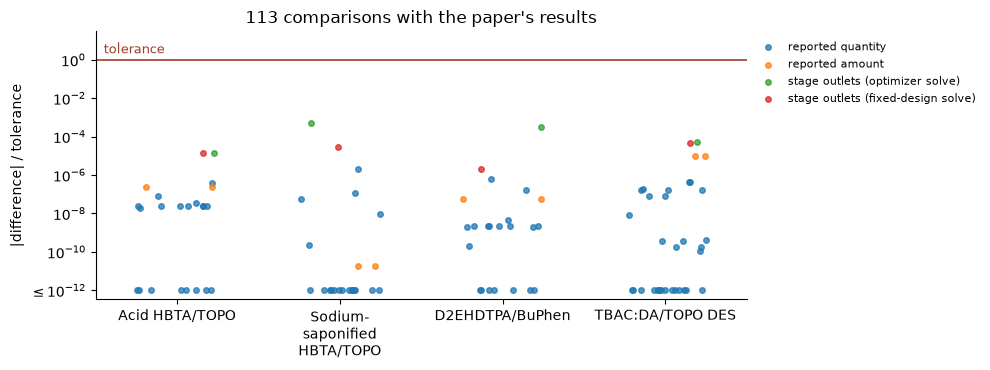

,comparisons,largest difference / tolerance,all within tolerance
Acid HBTA/TOPO,25,1.4e-05,✓
Sodium-saponified HBTA/TOPO,25,5.1e-04,✓
D2EHDTPA/BuPhen,25,3.1e-04,✓
TBAC:DA/TOPO DES,38,5.5e-05,✓


In [46]:
stage_summary, comparisons = sc.check_against_paper(solved)
stage_summary

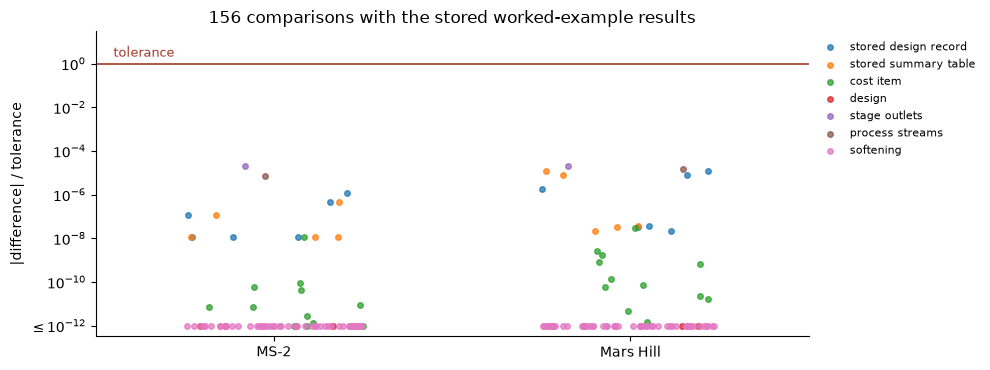

,comparisons,largest difference / tolerance,all within tolerance
MS-2,78,2.1e-05,✓
Mars Hill,78,2.1e-05,✓


In [47]:
process_summary, checks = pw.check_against_paper(results, softened)
process_summary

## Appendix

### A.1 How the equilibrium calculation sits inside the flowsheet

To IDAES the Engine is one more equation: given the amounts entering a stage, it returns the amounts leaving it. That is
why the same flowsheet can be simulated, optimized and connected to other units. This part looks inside the acid-form
cascade of Steps 4 to 7, so `m` goes back to that model and the whole process stays available as `process`. Called on
its own on the amounts entering stage 1, the Engine returns the same outlets the flowsheet holds:

In [48]:
process, m = m, acid_form
tools.engine_check(m, 1)

,direct Engine call (mol/L),flowsheet outlet (mol/L),difference (mol/L)
leaving stage 1,,,
water,55.5,55.5,7.11e-15
chloride-anion,2.81,2.81,4.44e-16
diluent,13,13,7.11e-15
LiA·T complex,0.00961,0.00961,1.42e-16
NaA·T complex,0.0288,0.0288,1.91e-16


The solver also needs each stage's first and second derivatives, which the Engine computes exactly from the ePC-SAFT
equilibrium conditions. Only the first derivatives, $\partial n^{out}_s / \partial n^{in}_q$, are checked here: they
agree with central finite differences to the accuracy of the finite differences.

In [49]:
tools.engine_derivatives(m, 1, "LiA·T complex")

,exact (Engine),finite difference,relative difference
"d n(out, LiA·T complex) / d n(in)",,,
entering diluent,-0.000146,-0.000146,2.65e-07
entering lithium-cation,0.283,0.283,2.6e-08
entering sodium-cation,-0.0011,-0.0011,5.54e-08
entering hydrogen-cation,-0.127,-0.127,1.73e-07
entering hbta,0.00438,0.00438,2.58e-08
entering NaA·T complex,0.13,0.13,5e-08
entering LiA·T complex,0.414,0.414,1.1e-07


### A.2 Optimize the acid-form design

Move the acid-form design to a weaker point, O/A = 1 and $c$ = 0.1 mol/L, and solve: the recovery drops. Then release
both variables inside the paper's bounds, $0.5 \le \mathrm{O/A} \le 3$ and $0.05 \le c \le 0.30$ mol/L, and let IPOPT
minimize the lithium left in the raffinate, subject to the flowsheet and $n_{LiA{\cdot}T,k} \le 0.72\,\mathrm{O/A}\cdot c$.

In [50]:
design = m.fs.design
design.organic_to_aqueous_ratio.fix(1.0)
design.extractant_mol_l.fix(0.1)
sc.initialize(m, brine)
tools.solve(m, "acid_hbta_topo_start")
starting = {
    "O/A": 1.0,
    "c (mol/L organic)": 0.1,
    "$E_{Li}$": 1
    - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"],
}
starting

{'O/A': 1.0, 'c (mol/L organic)': 0.1, '$E_{Li}$': 0.08627474365531596}

In [51]:
from pyomo.environ import Objective

design.organic_to_aqueous_ratio.unfix()
design.extractant_mol_l.unfix()
m.feasibility.deactivate()
m.raffinate_lithium = Objective(expr=m.fs.stage[3].outlet["lithium-cation"])
print("Degrees of freedom:", degrees_of_freedom(m))
tools.solve(m, "acid_hbta_topo_optimize")["kkt"]

Degrees of freedom: 2


{'stationarity': 1.1033129704990374e-12,
 'complementarity': 1.0001300346702136e-09,
 'feasibility': 5.894174037734956e-13,
 'multiplier_sign': 0.0}

The optimizer drives both variables to their upper bounds and recovers the paper's optimum: the design and the
recovery agree with the stored optimum within $3 \times 10^{-10}$ relative difference.

In [52]:
sc.optimum_table(m, brine, starting)

,starting design,optimized here,paper's optimum,relative difference
O/A,1,3,3,2.52e-07
c (mol/L organic),0.1,0.3,0.3,1.28e-07
$E_{Li}$,0.0863,0.397,0.397,2.08e-07


### A.3 Try other stage designs

Pick a solvent system, the number of stages and its design, then run the cell below the widgets. Each solve takes a few
seconds and is added to the comparison; a design that fails a check is listed with the reason. Widgets work only in a
running notebook (see the setup page beside this notebook).

In [53]:
designs = sc.DesignOptions()
designs

DesignOptions(children=(Dropdown(description='solvent system', layout=Layout(width='560px'), options=(('Acid H…

In [54]:
sc.run_design(designs)

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146


Every design solved so far, recovery against the sodium share of the loaded organic. Two designs start the comparison:
the acid form at O/A = 2 and D2EHDTPA/BuPhen with one stage.

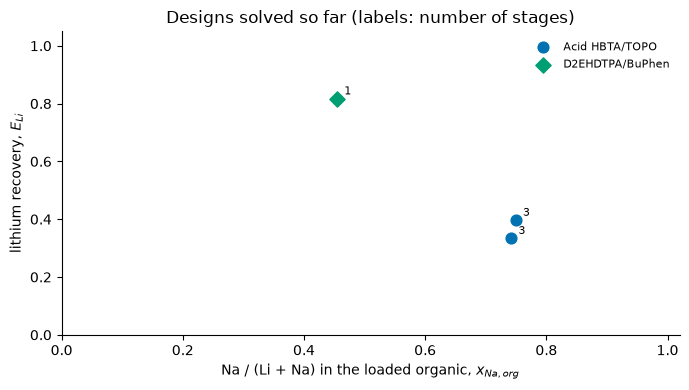

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146
1,Acid HBTA/TOPO,3,"O/A = 2, c = 0.3 (upper bound)",0.334,46.4,0.742,23.3,0.0161
2,D2EHDTPA/BuPhen,1,"O/A = 1.82, B = 1.0 (upper bound), S = 1.5 (up...",0.817,760,0.455,-19.8,0.00442


In [55]:
designs.system.label, designs.stages.value = "Acid HBTA/TOPO", 3
designs.sliders.children[0].value = 2.0
sc.run_design(designs)
designs.system.label, designs.stages.value = "D2EHDTPA/BuPhen", 1
sc.run_design(designs)
sc.compare_designs()

### A.4 Price sensitivity of the MS-2 operating cost

Scale each group of prices of the worked example and see the operating cost and break-even price move. The flows stay
at the solved design, so this is a price sensitivity, not a new optimization.

In [56]:
pw.price_sensitivity(process, result)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='softening reagents', layout…

### A.5 Other waters, prices and stage counts

The worked-example basis has stored designs for four waters (MS-2, BR-2, Mars Hill, Westmoreland). Pick a water, a
price case, the exchange-constant fit, the number of stages, and whether to read the stored result, solve that design,
or let IPOPT choose the HBTA concentration that minimizes the cost per kg of lithium (a few seconds to about five
minutes). Run the cell below the widgets; each run adds a row to the comparison.

In [57]:
options = pw.Options()
options

Options(children=(Dropdown(description='produced water', layout=Layout(width='620px'), options=(('MS-2', 'MS2'…

In [58]:
pw.run_selection(options)

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/t LCE)
0,MS-2,base,single-stage fit,5,the stored result,optimized,0.1,99.5,69,228,"1,968","369,748"


The stored designs of all four waters at base prices with the single-stage fit, beside everything run so far. Cost per
kg of lithium falls as the water's lithium rises, from Westmoreland (117 mg/L) to Mars Hill (423 mg/L).

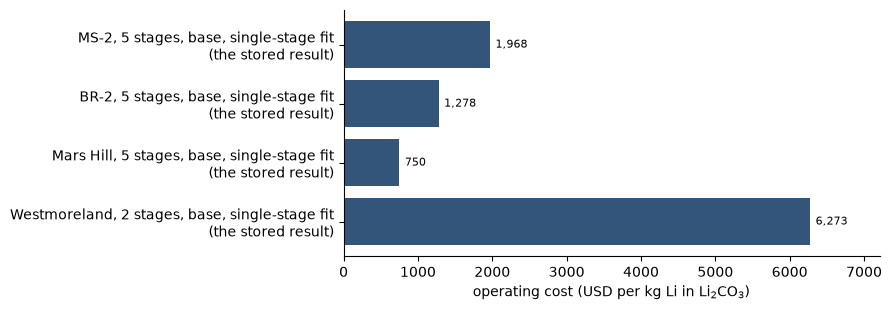

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/t LCE)
0,MS-2,base,single-stage fit,5,the stored result,optimized,0.1,99.5,69,228,"1,968","369,748"
1,BR-2,base,single-stage fit,5,the stored result,optimized,0.1,99,66.7,215,"1,278","240,019"
2,Mars Hill,base,single-stage fit,5,the stored result,optimized,0.114,95,64.3,204,750,"140,947"
3,Westmoreland,base,single-stage fit,2,the stored result,optimized,0.1,97.3,73.6,540,"6,273","1,178,453"


In [59]:
pw.add_selected_designs()